# Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [2]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)


Número de estados: 500
Número de acciones: 6


### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.


**Respuesta.** Taxi tiene 500 estados y 6 acciones. El número de estados es mucho mayor que en FrozenLake porque cada estado combina las 25 posiciones del taxi, las 5 ubicaciones posibles del pasajero (cuatro paradas o dentro del taxi) y los 4 destinos, lo que da 25 por 5 por 4 combinaciones. En FrozenLake el estado solo codifica la casilla del agente.

## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [3]:
state, info = env.reset(seed=42)

env.action_space.seed(SEED)
action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 0
Nuevo estado: 486
Recompensa: -1
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?


**Respuesta.** El estado actual s_t es 386 y codifica en un solo entero la posición del taxi, la ubicación del pasajero y el destino. La acción a_t es 0, que corresponde a moverse al sur. La recompensa r_{t+1} es 1 negativo, el costo fijo por cada paso. El nuevo estado s_{t+1} es 486, que representa al taxi una fila más abajo con el mismo pasajero y destino.

## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$


**Respuesta.** Deben aprenderse 500 por 6, es decir 3000 valores Q.

## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [5]:
def choose_action(Q, state, epsilon, env):
    # Exploración con probabilidad epsilon
    if random.random() < epsilon:
        return env.action_space.sample()
    # Explotación con desempate aleatorio entre las mejores acciones
    best_actions = np.flatnonzero(Q[state] == Q[state].max())
    return int(np.random.choice(best_actions))

## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [6]:
def update_q(Q, state, action, reward, next_state, alpha, gamma, terminated=False):
    # En un estado terminal no se suma valor futuro
    future = 0.0 if terminated else np.max(Q[next_state])
    target = reward + gamma * future
    td_error = target - Q[state, action]
    Q[state, action] += alpha * td_error
    return td_error

## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [7]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []
    env.action_space.seed(SEED)

    for episode in range(episodes):
        state, _ = env.reset(seed=SEED + episode)
        total_reward = 0

        for _ in range(max_steps):
            action = choose_action(Q, state, epsilon, env)
            next_state, reward, terminated, truncated, _ = env.step(action)
            update_q(Q, state, action, reward, next_state, alpha, gamma, terminated)
            state = next_state
            total_reward += reward
            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards

## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [8]:
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


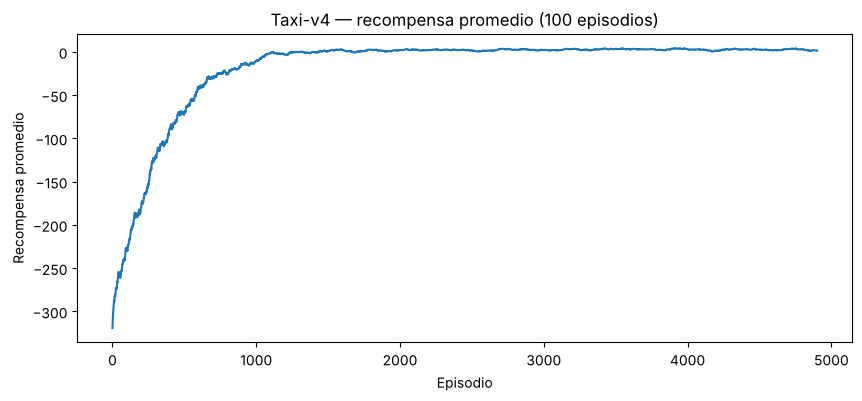

In [9]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v4 — recompensa promedio ({window} episodios)")
plt.show()


### Pregunta 4

Describa la curva de aprendizaje.

- ¿La recompensa promedio mejora?
- ¿Después de aproximadamente cuántos episodios comienza a estabilizarse?
- ¿El comportamiento observado indica convergencia perfecta o solamente una política razonablemente buena?


**Respuesta.** La recompensa promedio mejora de forma clara. Se parte de valores cercanos a 300 negativo, propios de un comportamiento aleatorio con muchas acciones ilegales, y hacia el episodio 1500 el promedio ya es positivo. Desde ahí la curva se estabiliza alrededor de valores entre 0 y 3 con pequeñas oscilaciones. Esto indica una política razonablemente buena más que una convergencia perfecta, porque durante el entrenamiento se mantiene un 10 % de acciones aleatorias que penalizan el promedio.

## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [10]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [11]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


error: XDG_RUNTIME_DIR is invalid or not set in the environment.


Recompensa total sin entrenamiento: -203


Ahora observe el agente entrenado.


In [12]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


### Pregunta 5

Compare los dos episodios.

- ¿Qué diferencias observa en el comportamiento del taxi?
- ¿El taxi sin entrenamiento logra completar la tarea?
- ¿El agente entrenado evita acciones innecesarias?
- ¿Qué evidencia visual le permite afirmar que el agente aprendió?


**Respuesta.** El taxi sin entrenamiento se mueve sin rumbo, repite acciones ilegales de recoger o dejar y no completa la tarea, terminando con una recompensa de 203 negativo en 50 pasos. El agente entrenado va directo a la parada del pasajero, lo recoge, se dirige al destino y lo deja con una recompensa total de 10. No ejecuta recogidas ni entregas ilegales y no da vueltas innecesarias. La evidencia visual es la trayectoria corta y dirigida en la animación y la terminación exitosa del episodio.

## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [13]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-1.27399828 -3.00496938 -1.2629688   3.94947757 -5.45461709 -6.81526948]
Mejor acción: 3


### Pregunta 6

Para el estado seleccionado:

1. ¿Cuál es la acción con mayor valor Q?
2. ¿Qué significa que una acción tenga un valor Q mayor que otra?
3. ¿Por qué no podemos interpretar $Q(s,a)$ únicamente como la recompensa inmediata de ejecutar la acción?


**Respuesta.** Para el estado 123 la acción con mayor valor Q es la 3, que corresponde a moverse hacia el oeste. Que una acción tenga un Q mayor significa que se espera obtener mayor retorno descontado acumulado si se ejecuta esa acción y luego se sigue la política aprendida. Q(s,a) no puede interpretarse solo como recompensa inmediata porque casi todos los movimientos dan 1 negativo, y la diferencia entre acciones proviene del término gamma por max Q(s',a') que propaga el valor de llegar al destino.

## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

### Pregunta 7

Compare el nuevo entrenamiento con el original.

Explique cómo el cambio del hiperparámetro afectó:

- velocidad de aprendizaje,
- estabilidad,
- recompensa final,
- comportamiento observado.


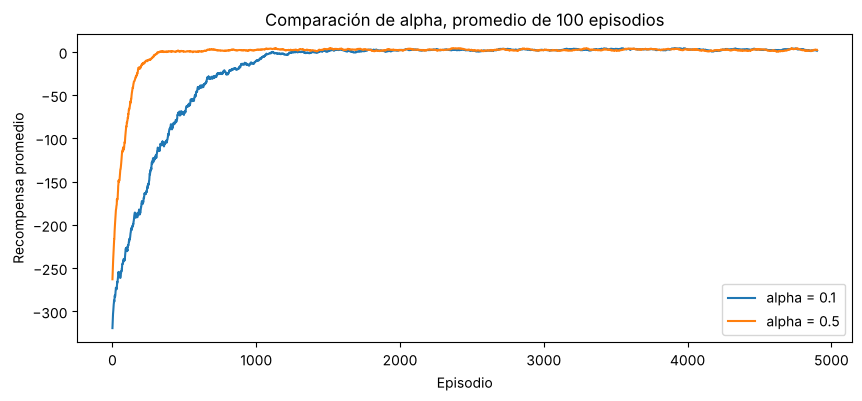

alpha = 0.1: recompensa greedy media 8.20, éxito 100%, primer promedio positivo en el episodio 1271
alpha = 0.5: recompensa greedy media 8.13, éxito 100%, primer promedio positivo en el episodio 327


In [14]:
# Se modifica solo alpha de 0.1 a 0.5
Q_alpha, rewards_alpha = train_q_learning(
    env,
    np.zeros((n_states, n_actions)),
    episodes=5000,
    alpha=0.5,
    gamma=0.95,
    epsilon=0.1
)

ma_alpha = np.convolve(rewards_alpha, np.ones(window) / window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(moving_average, label="alpha = 0.1")
plt.plot(ma_alpha, label="alpha = 0.5")
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Comparación de alpha, promedio de {window} episodios")
plt.legend()
plt.show()

def evaluate(Q, n=200):
    totals = []
    for i in range(n):
        s, _ = env.reset(seed=10_000 + i)
        total = 0
        for _ in range(200):
            s, r, term, trunc, _ = env.step(int(np.argmax(Q[s])))
            total += r
            if term or trunc:
                break
        totals.append(total)
    return np.mean(totals), np.mean(np.array(totals) > 0)

for name, Qx, rw in [("alpha = 0.1", Q_trained, rewards), ("alpha = 0.5", Q_alpha, rewards_alpha)]:
    mean_r, success = evaluate(Qx)
    first = next((i for i in range(len(rw) - window) if np.mean(rw[i:i + window]) > 0), None)
    print(f"{name}: recompensa greedy media {mean_r:.2f}, éxito {success:.0%}, primer promedio positivo en el episodio {first}")

**Respuesta.** Se modificó únicamente alpha, pasando de 0.1 a 0.5. Con alpha mayor el aprendizaje es mucho más rápido, ya que el promedio móvil se vuelve positivo cerca del episodio 330 frente a cerca del 1270 con el valor original. La estabilidad final es similar porque Taxi es un ambiente determinista, donde una tasa alta no introduce ruido importante en las actualizaciones. La recompensa final con política greedy es prácticamente la misma, alrededor de 8 por episodio y 100 % de éxito en ambos casos. En el comportamiento observado los dos agentes resuelven la tarea con rutas cortas.

## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.
